## Select Valid (all not nan) Column Associated with Kelvin Wave Events

### Import package

In [1]:
# Limit numerical libraries and scikit-learn to one CPU thread
import os

for variable in (
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "BLIS_NUM_THREADS",
):
    os.environ[variable] = "1"


import numpy as np
import netCDF4 as nc

from sklearn.linear_model import Ridge

from matplotlib import pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import os

### Acquire linear response function

#### Load data

In [2]:
# Load significant events
time_idx: np.ndarray = np.loadtxt(
    "/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/significant_time_idx.txt"
)

lon_val: np.ndarray = np.loadtxt(
    "/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/significant_lon_value.txt"
)

# Load data with removing first 3 harmonics
with nc.Dataset("/data92/b11209013/ERA5_GRIB/Data/tropical_-10_10/w.nc", "r") as w_ds:

    era5_coords: dict[str, np.ndarray] = {
        key: w_ds.variables[key][...]
        for key in w_ds.dimensions.keys()
    }

    lat_lim = (era5_coords["lat"] >= -5.0) & (era5_coords["lat"] <= 5.0)

    w: np.ndarray = w_ds.variables["w"][..., lat_lim, :].astype(np.float32)

# Load CloudSat
with nc.Dataset("/data92/b11209013/CloudSat/DATA/QR_gridded_15layer_-5_5.nc", "r") as cs_ds:

    LW: np.ndarray = cs_ds.variables["QLW"][...].astype(np.float32)
    SW: np.ndarray = cs_ds.variables["QSW"][...].astype(np.float32)

#### Preprocessing

In [3]:
# remove time and zonal mean
w_anom : np.ndarray = w  - np.nanmean(w, axis=(0, -1), keepdims=True)
LW_anom: np.ndarray = LW - np.nanmean(LW, axis=(0, -1), keepdims=True)
SW_anom: np.ndarray = SW - np.nanmean(SW, axis=(0, -1), keepdims=True)

del w, LW, SW

#### Select time and longitude based on OLR-based events

In [4]:
# convert OLR-based longitude values to longitude index
lon_idx: np.ndarray = np.array([
    np.argmin(np.abs(era5_coords["lon"] - l))
    for l in lon_val
])

x_half = w_anom.shape[-1]//2

# select time slice and centering
w_sel, LW_sel, SW_sel = [], [], []

for (i, ti) in enumerate(time_idx):

    ti = int(ti)

    w_sel.append(np.roll(w_anom[ti], shift=x_half - lon_idx[i], axis=-1))
    LW_sel.append(np.roll(LW_anom[ti], shift=x_half - lon_idx[i], axis=-1))
    SW_sel.append(np.roll(SW_anom[ti], shift=x_half - lon_idx[i], axis=-1))

# Convert selected snapshots into array
w_sel_array : np.ndarray = np.array(w_sel).transpose(1, 3, 0, 2) # shape: (nz, nx, nt, ny)
LW_sel_array: np.ndarray = np.array(LW_sel).transpose(1, 3, 0, 2) # shape: (nz, nx, nt, ny)
SW_sel_array: np.ndarray = np.array(SW_sel).transpose(1, 3, 0, 2) # shape: (nz, nx, nt, ny)

del w_sel, LW_sel, SW_sel

#### Find valid column

In [5]:
# masking
LW_finite = np.isfinite(np.ma.filled(LW_sel_array, np.nan))
SW_finite = np.isfinite(np.ma.filled(SW_sel_array, np.nan))

valid_mask = np.all(LW_finite & SW_finite, axis=0)

# filter for the three arrays
w_valid : np.ndarray = w_sel_array[:, valid_mask]
LW_valid: np.ndarray = LW_sel_array[:, valid_mask]
SW_valid: np.ndarray = SW_sel_array[:, valid_mask]

#### Fit the LW–w and SW–w Jacobian matrices


In [6]:
# apply Ridge regression
LW_model: Ridge = Ridge(alpha=1, solver="svd")
LW_model.fit(w_valid.T, LW_valid.T)

SW_model: Ridge = Ridge(alpha=1, solver="svd")
SW_model.fit(w_valid.T, SW_valid.T)

J_LW = LW_model.coef_
J_SW = SW_model.coef_

#### Save Jacobians and associated files


In [7]:
np.savetxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/Jacob_LW.txt", J_LW)
np.savetxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/Jacob_SW.txt", J_SW)

np.savetxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/plev.txt", era5_coords["plev"])

### Use composite for verification

#### Load composite fields

In [8]:
# Load LW composite profile
LW_composite: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/LW_composite.txt")

# Load SW composite profile
SW_composite: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/SW_composite.txt")

# Load w composite profile
w_composite: np.ndarray = np.loadtxt("/home/b11209013/KW_CloudSat/Files/ERA5_GRIB/w_composite.txt")

#### Calculate prediction with composite vertical motion

In [9]:
LW_prediction: np.ndarray = J_LW @ w_composite

SW_prediction: np.ndarray = J_SW @ w_composite

#### Spatial verification: prediction shading and observed contours

Overlay the Jacobian prediction (shading) and CloudSat composite (black
contours) within −50° to 50° relative longitude. Shading uses a shared scale
based on the predicted LW/SW magnitudes so the predicted spatial pattern
remains visible. Contour labels give the observed heating rates in K day⁻¹;
positive contours are solid and negative contours are dashed. Contours use
every third longitude point to reduce visual clutter. Gray shading indicates
missing predictions.

The annotation reports centered pattern correlation over the same finite
pressure–longitude pairs used in the scatter comparison. The right panel
compares the observed and predicted longitude-mean vertical profiles on their
original amplitude scale, using matched finite samples at each pressure.
Its shaded gap shows the difference between the means, not uncertainty.

Figures are displayed inline and saved as 300-dpi PNG and PDF files.


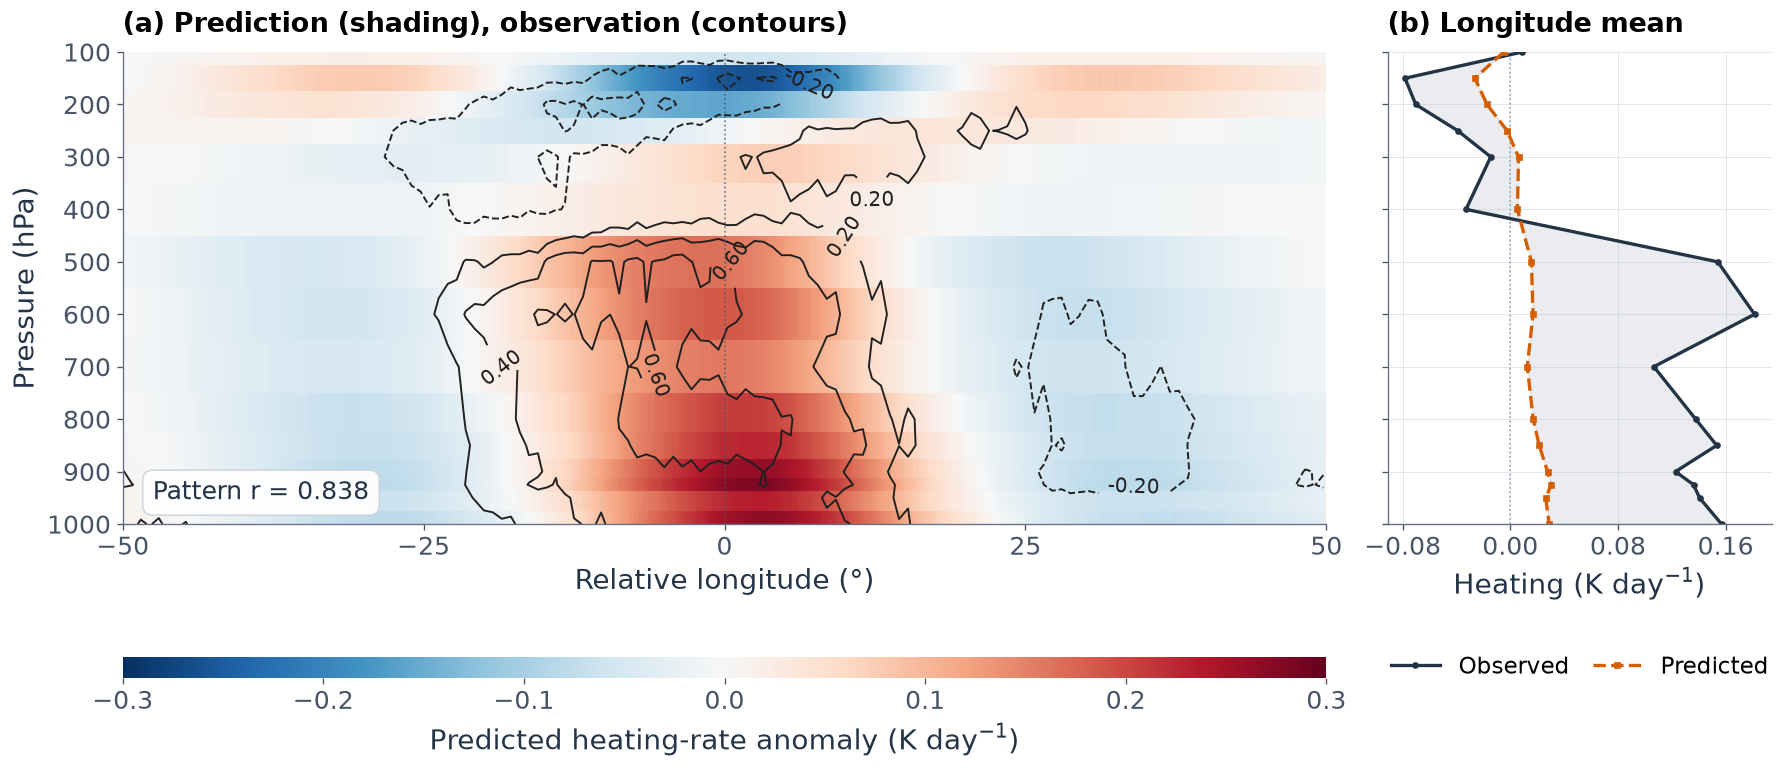

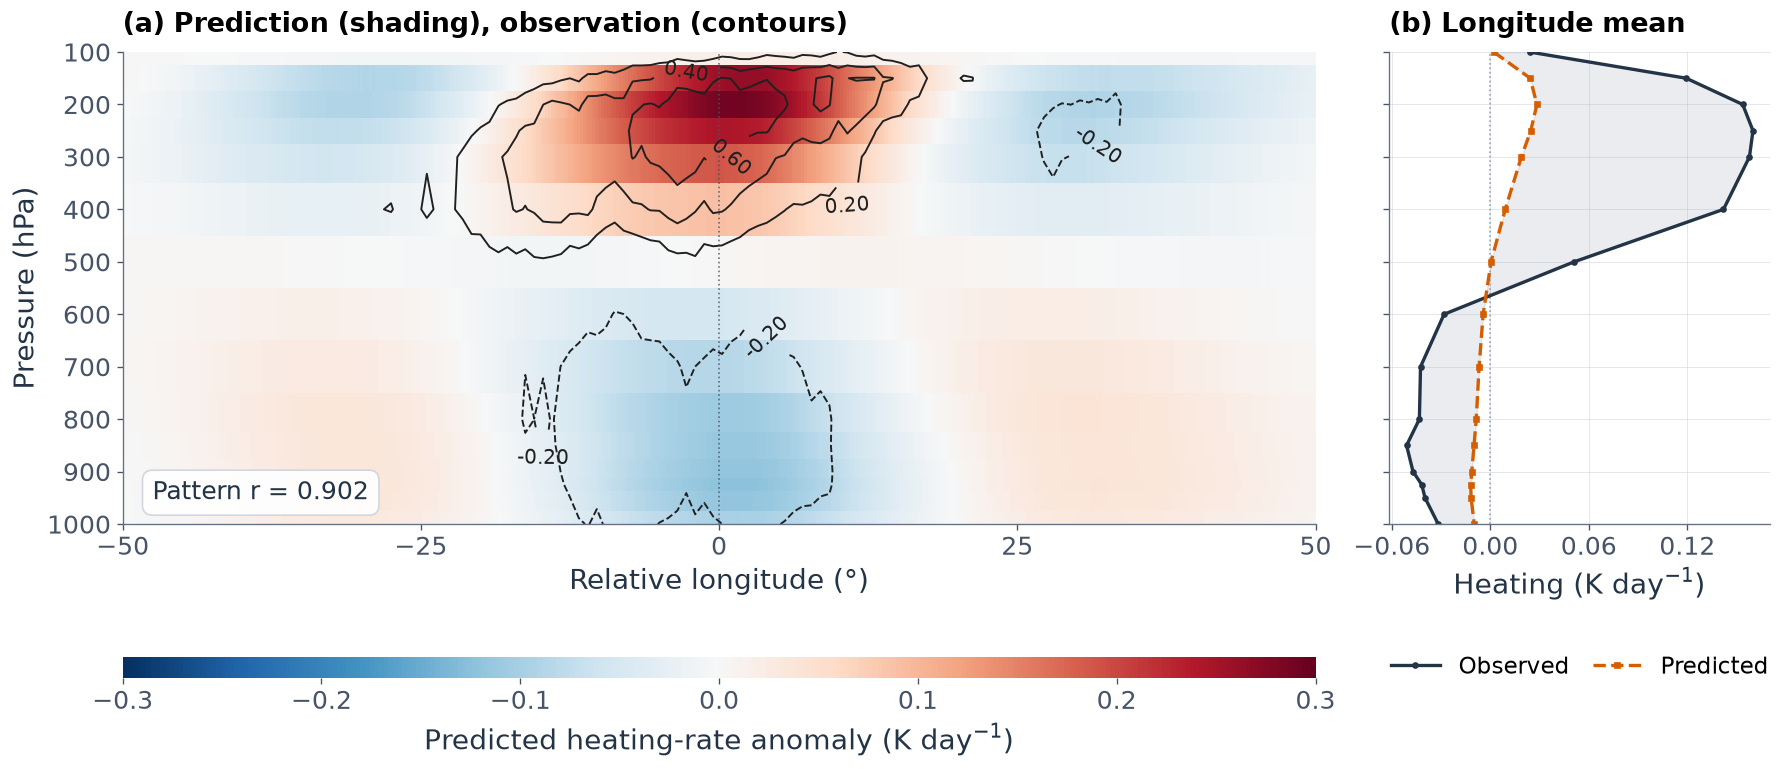

In [ ]:
from pathlib import Path
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator

# Consistent typography, colors, and units for all verification figures.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 16,
    "mathtext.fontset": "dejavusans",
    "axes.labelsize": 17,
    "axes.titlesize": 17,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": "#667085",
    "axes.labelcolor": "#243447",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#475467",
    "ytick.color": "#475467",
    "legend.fontsize": 14,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

figure_dir = Path("/home/b11209013/KW_CloudSat/Figure/ERA5_GRIB")
figure_dir.mkdir(parents=True, exist_ok=True)
observed_color, predicted_color = "#243447", "#D55E00"
heating_cmap = plt.get_cmap("RdBu_r").copy()
heating_cmap.set_bad("#E9EDF2")
heating_units = r"K day$^{-1}$"

dlon = float(np.abs(np.diff(era5_coords["lon"][:2]))[0])
relative_lon = (np.arange(LW_prediction.shape[-1]) - LW_prediction.shape[-1] // 2) * dlon
pressure_hpa = np.asarray(era5_coords["plev"], dtype=float) / 100.0
comparison_window = (-50.0, 50.0)
lon_window = (relative_lon >= comparison_window[0]) & (relative_lon <= comparison_window[1])
if not lon_window.any():
    raise ValueError("No longitude points fall inside the comparison window")


def finite_array(values):
    """Keep masked NetCDF values missing when converting to a float array."""
    return np.ma.asarray(values, dtype=float).filled(np.nan)


def calculate_pattern_metrics(prediction, composite):
    """Centered pattern r and standard-deviation ratio on finite paired values."""
    prediction, composite = finite_array(prediction), finite_array(composite)
    if prediction.shape != composite.shape:
        raise ValueError("Prediction and composite must have matching shapes")
    valid = np.isfinite(prediction) & np.isfinite(composite)
    predicted, observed = prediction[valid], composite[valid]
    result = {"r": np.nan, "amplitude_ratio": np.nan, "n_pairs": int(valid.sum())}
    if predicted.size < 2 or np.all(observed == observed[0]):
        return result
    if np.all(predicted == predicted[0]):
        result["amplitude_ratio"] = 0.0
        return result
    predicted_centered = predicted - predicted.mean()
    observed_centered = observed - observed.mean()
    predicted_norm = np.linalg.norm(predicted_centered)
    observed_norm = np.linalg.norm(observed_centered)
    result["amplitude_ratio"] = float(predicted_norm / observed_norm)
    result["r"] = float(np.clip(
        np.dot(predicted_centered / predicted_norm, observed_centered / observed_norm),
        -1.0, 1.0,
    ))
    return result


def calculate_comparison_metrics(prediction, composite):
    """Use identical pairs for pattern correlation, R2, RMSE, and mean bias."""
    result = calculate_pattern_metrics(prediction, composite)
    prediction, composite = finite_array(prediction), finite_array(composite)
    valid = np.isfinite(prediction) & np.isfinite(composite)
    predicted, observed = prediction[valid], composite[valid]
    result.update(r2=np.nan, rmse=np.nan, bias=np.nan)
    if observed.size:
        difference = predicted - observed
        result["rmse"] = float(np.sqrt(np.mean(difference**2)))
        result["bias"] = float(difference.mean())
        if observed.size >= 2 and np.any(observed != observed[0]):
            result["r2"] = float(1.0 - np.sum(difference**2)
                                 / np.sum((observed - observed.mean())**2))
    return result


def metric_label(value, digits=3):
    return f"{value:.{digits}f}" if np.isfinite(value) else "undefined"


def symmetric_limit(*fields):
    """Round the largest finite magnitude up without clipping any data."""
    peak = max((np.max(np.abs(a[np.isfinite(a)]))
                for field in fields
                if np.isfinite(a := finite_array(field)).any()), default=0.0)
    if peak == 0.0:
        return 1.0
    step = 10.0 ** np.floor(np.log10(peak)) / 2.0
    return float(np.ceil(peak / step) * step)


def save_verification_figure(fig, stem):
    for extension in ("png", "pdf"):
        fig.savefig(figure_dir / f"{stem}.{extension}", bbox_inches="tight",
                    facecolor="white")


# Use a common prediction scale for LW/SW spatial-pattern overlays.
# Observed contour labels retain their original heating-rate units.
heating_limit = symmetric_limit(LW_prediction[:, lon_window], SW_prediction[:, lon_window])
heating_norm = TwoSlopeNorm(vmin=-heating_limit, vcenter=0.0, vmax=heating_limit)

def plot_prediction_verification(prediction, composite, component):
    """Overlay predicted shading and observed contours, with mean profiles."""
    prediction, composite = finite_array(prediction), finite_array(composite)
    if prediction.shape != composite.shape or prediction.shape != (pressure_hpa.size, relative_lon.size):
        raise ValueError("Heating fields must match the pressure and longitude coordinates")
    longitude = relative_lon[lon_window]
    predicted, observed = prediction[:, lon_window], composite[:, lon_window]
    metrics = calculate_pattern_metrics(predicted, observed)

    fig = plt.figure(figsize=(14.8, 6.3), layout="constrained")
    grid = fig.add_gridspec(2, 2, height_ratios=(1.0, 0.045),
                           width_ratios=(3.6, 1.15), hspace=0.12)
    ax_overlay = fig.add_subplot(grid[0, 0])
    ax_mean = fig.add_subplot(grid[0, 1], sharey=ax_overlay)

    mesh = ax_overlay.pcolormesh(
        longitude, pressure_hpa, np.ma.masked_invalid(predicted),
        cmap=heating_cmap, norm=heating_norm, shading="nearest", rasterized=True,
    )
    observed_for_contours = observed[:, ::3]
    finite_observed = observed_for_contours[np.isfinite(observed_for_contours)]
    observed_limit = symmetric_limit(observed)
    contour_levels = MaxNLocator(nbins=8, symmetric=True, steps=[1, 2, 5, 10]).tick_values(-observed_limit, observed_limit)
    contour_levels = contour_levels[contour_levels != 0.0]
    if finite_observed.size:
        contour_levels = contour_levels[
            (contour_levels > finite_observed.min()) & (contour_levels < finite_observed.max())
        ]
        if contour_levels.size and observed_for_contours.shape[1] >= 2:
            contours = ax_overlay.contour(
                longitude[::3], pressure_hpa, np.ma.masked_invalid(observed_for_contours),
                levels=contour_levels, colors="#202020", linewidths=1.15,
                linestyles=["dashed" if level < 0 else "solid" for level in contour_levels],
            )
            ax_overlay.clabel(contours, inline=True, fontsize=12, fmt="%.2f", inline_spacing=5)
    ax_overlay.axvline(0.0, color="#475467", ls=":", lw=1.0, alpha=0.8)
    ax_overlay.set(xlim=comparison_window, xlabel="Relative longitude (°)", ylabel="Pressure (hPa)")
    ax_overlay.set_xticks([-50, -25, 0, 25, 50])
    ax_overlay.set_title("(a) Prediction (shading), observation (contours)", pad=12, fontsize=16)
    ax_overlay.text(
        0.025, 0.04, f"Pattern r = {metric_label(metrics['r'])}", transform=ax_overlay.transAxes,
        fontsize=15, color="#243447", ha="left", va="bottom",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#D0D5DD", alpha=0.94),
    )

    # Compare amplitudes using exactly the same finite longitudes at each level.
    valid = np.isfinite(predicted) & np.isfinite(observed)
    count = valid.sum(axis=1)
    predicted_mean = np.divide(np.where(valid, predicted, 0.0).sum(axis=1), count,
                               out=np.full(pressure_hpa.size, np.nan), where=count > 0)
    observed_mean = np.divide(np.where(valid, observed, 0.0).sum(axis=1), count,
                              out=np.full(pressure_hpa.size, np.nan), where=count > 0)
    ax_mean.axvline(0.0, color="#98A2B3", ls=":", lw=1.0)
    ax_mean.fill_betweenx(pressure_hpa, observed_mean, predicted_mean, color="#98A2B3", alpha=0.2)
    ax_mean.plot(observed_mean, pressure_hpa, color=observed_color, lw=2,
                 marker="o", ms=3, label="Observed")
    ax_mean.plot(predicted_mean, pressure_hpa, color=predicted_color, lw=2,
                 ls="--", marker="s", ms=3, label="Predicted")
    ax_mean.set_title("(b) Longitude mean", pad=12, fontsize=16)
    ax_mean.set_xlabel(f"Heating ({heating_units})")
    ax_mean.xaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3))
    ax_mean.grid(axis="both", color="#D0D5DD", lw=0.6, alpha=0.55)
    ax_mean.set_axisbelow(True)
    ax_mean.tick_params(labelleft=False)
    for ax in (ax_overlay, ax_mean):
        ax.set_ylim(pressure_hpa.max(), pressure_hpa.min())
        ax.set_yticks(np.arange(100, 1001, 100))

    legend_ax = fig.add_subplot(grid[1, 1])
    legend_ax.set_axis_off()
    handles, labels = ax_mean.get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=2, columnspacing=1.0, handlelength=2.1)
    colorbar = fig.colorbar(mesh, cax=fig.add_subplot(grid[1, 0]), orientation="horizontal")
    colorbar.set_label(f"Predicted heating-rate anomaly ({heating_units})", labelpad=5)
    colorbar.locator = MaxNLocator(nbins=7, symmetric=True)
    colorbar.update_ticks()
    colorbar.outline.set_visible(False)
    save_verification_figure(fig, component)
    return fig

for component, prediction, composite in (
    ("Longwave", LW_prediction, LW_composite),
    ("Shortwave", SW_prediction, SW_composite),
):
    profile_fig = plot_prediction_verification(prediction, composite, component)
    plt.show()
    plt.close(profile_fig)


#### Scatter verification: pattern correlation, R², and amplitude

Each hexagon counts paired observed and predicted heating values at matching
pressure and relative longitude within −50° to 50°. Logarithmic count shading
reveals dense regions without overplotting. Both panels have the same axis
limits, equal aspect ratio, count scale, and dashed 1:1 reference.

**Pattern r** is the centered Pearson correlation of the flattened spatial
fields, computed using only finite pairs with equal weight. **R²** is
1 − Σ(observed − predicted)² / Σ(observed − mean(observed))²; it is calculated
from the existing predictions. **σP/σO** measures the predicted-to-observed
standard-deviation ratio. RMSE and mean bias (predicted minus observed) are in
K day⁻¹. These are composite diagnostics, not an independent held-out test.


LW: pattern r = 0.8377, R2 = 0.3967, Std(P)/Std(O) = 0.3415, RMSE = 0.1934, bias = -0.0604, N = 6,015
SW: pattern r = 0.9023, R2 = 0.4733, Std(P)/Std(O) = 0.3379, RMSE = 0.1452, bias = -0.0299, N = 6,015


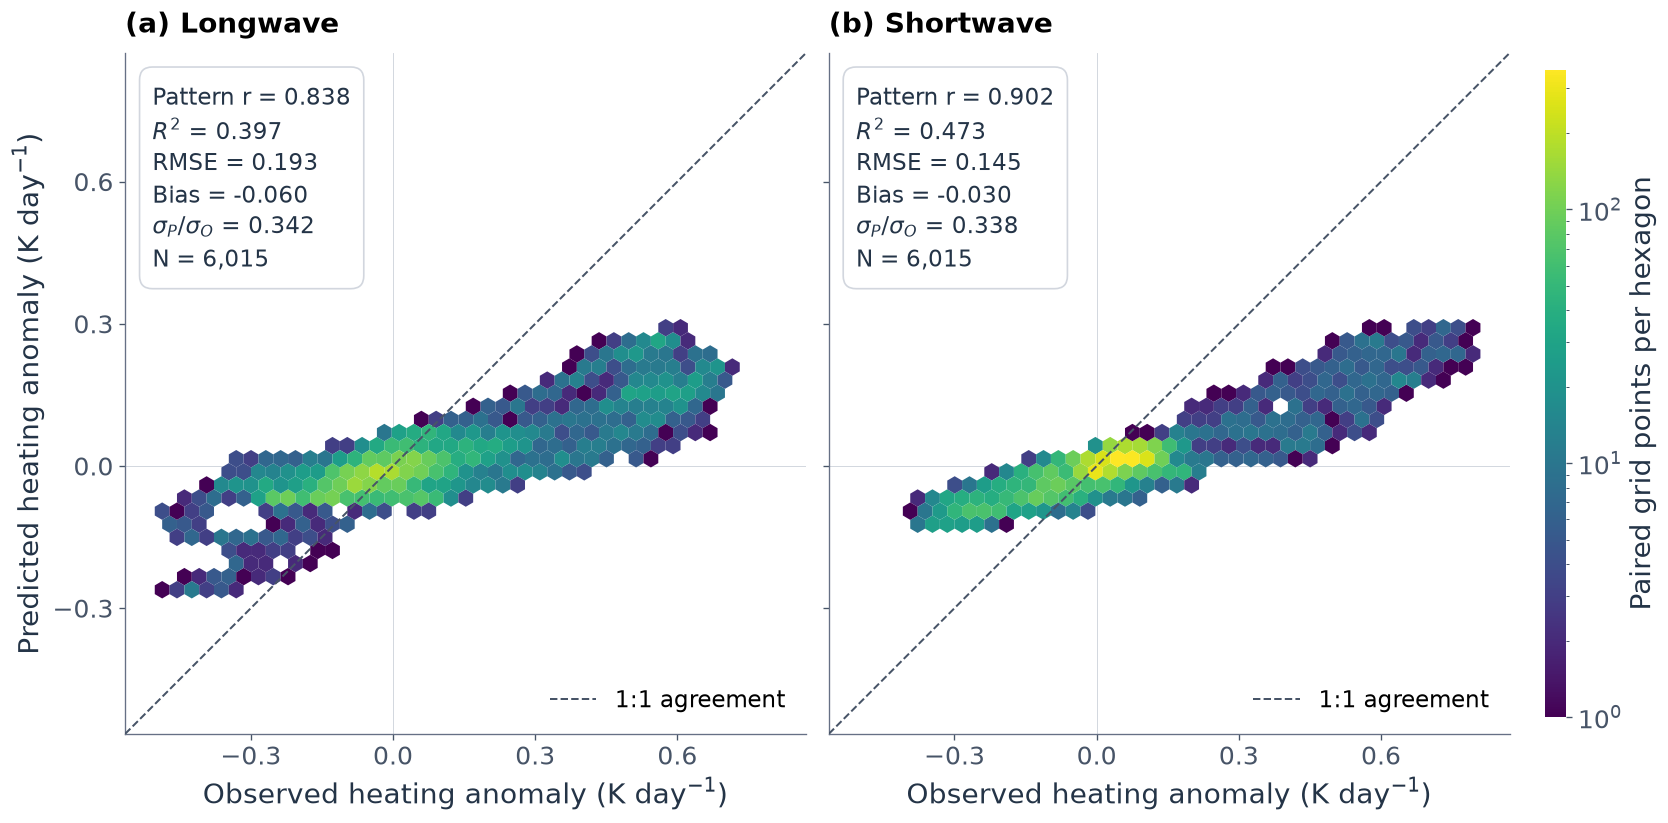

In [ ]:
def plot_composite_scatter(predictions, composites, longitude, window=(-50.0, 50.0)):
    """Compare paired grid values with common axes, density scale, and metrics."""
    longitude = np.asarray(longitude)
    selected_lon = (longitude >= window[0]) & (longitude <= window[1])
    if not selected_lon.any():
        raise ValueError("No longitude points fall inside the scatter window")
    pairs, metrics = {}, {}
    for component in ("LW", "SW"):
        prediction = finite_array(predictions[component])
        composite = finite_array(composites[component])
        if prediction.ndim != 2 or prediction.shape != composite.shape or prediction.shape[-1] != longitude.size:
            raise ValueError(f"{component}: prediction, composite, and longitude shapes must match")
        predicted, observed = prediction[:, selected_lon], composite[:, selected_lon]
        metrics[component] = calculate_comparison_metrics(predicted, observed)
        valid = np.isfinite(predicted) & np.isfinite(observed)
        pairs[component] = (observed[valid], predicted[valid])

    finite_values = [values for pair in pairs.values() for values in pair if values.size]
    if finite_values:
        lower, upper = min(a.min() for a in finite_values), max(a.max() for a in finite_values)
        padding = 0.06 * (upper - lower) if upper > lower else 0.05 * max(abs(lower), 1.0)
        limits = (lower - padding, upper + padding)
    else:
        limits = (-1.0, 1.0)

    fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.9), sharex=True, sharey=True,
                             layout="constrained")
    density_artists = []
    scores = {}
    for ax, component, title in zip(axes, ("LW", "SW"), ("(a) Longwave", "(b) Shortwave")):
        observed, predicted = pairs[component]
        metric = metrics[component]
        if observed.size:
            density = ax.hexbin(observed, predicted, gridsize=46, mincnt=1,
                                extent=(*limits, *limits), cmap="viridis",
                                linewidths=0, rasterized=True)
            density_artists.append(density)
        ax.plot(limits, limits, color="#475467", ls="--", lw=1.2,
                label="1:1 agreement", zorder=3)
        ax.axhline(0.0, color="#98A2B3", lw=0.5, alpha=0.5, zorder=0)
        ax.axvline(0.0, color="#98A2B3", lw=0.5, alpha=0.5, zorder=0)
        ax.set(xlim=limits, ylim=limits, aspect="equal",
               xlabel=f"Observed heating anomaly ({heating_units})")
        ax.set_title(title, pad=12)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.legend(loc="lower right", fontsize=14)
        annotation = (
            f"Pattern r = {metric_label(metric['r'])}\n"
            f"$R^2$ = {metric_label(metric['r2'])}\n"
            f"RMSE = {metric_label(metric['rmse'])}\n"
            f"Bias = {metric_label(metric['bias'])}\n"
            rf"$\sigma_P / \sigma_O$ = {metric_label(metric['amplitude_ratio'])}"
            f"\nN = {metric['n_pairs']:,}"
        )
        ax.text(0.04, 0.96, annotation, transform=ax.transAxes, ha="left", va="top",
                fontsize=14, linespacing=1.4, color="#243447",
                bbox=dict(boxstyle="round,pad=0.55", fc="white", ec="#D0D5DD", alpha=0.96))
        scores[component] = metric["r2"]
        print(f"{component}: pattern r = {metric_label(metric['r'], 4)}, "
              f"R2 = {metric_label(metric['r2'], 4)}, "
              f"Std(P)/Std(O) = {metric_label(metric['amplitude_ratio'], 4)}, "
              f"RMSE = {metric_label(metric['rmse'], 4)}, "
              f"bias = {metric_label(metric['bias'], 4)}, N = {metric['n_pairs']:,}")

    if density_artists:
        maximum_count = max(float(artist.get_array().max()) for artist in density_artists)
        count_norm = LogNorm(vmin=1.0, vmax=max(2.0, maximum_count))
        for artist in density_artists:
            artist.set_norm(count_norm)
        colorbar = fig.colorbar(density_artists[0], ax=axes, shrink=0.82, pad=0.025, aspect=30)
        colorbar.set_label("Paired grid points per hexagon")
        colorbar.outline.set_visible(False)
    axes[0].set_ylabel(f"Predicted heating anomaly ({heating_units})")
    return fig, scores


scatter_fig, composite_r2 = plot_composite_scatter(
    {"LW": LW_prediction, "SW": SW_prediction},
    {"LW": LW_composite, "SW": SW_composite},
    relative_lon, window=comparison_window,
)
save_verification_figure(scatter_fig, "LW_SW_prediction_scatter")
plt.show()
plt.close(scatter_fig)


#### Numerical summary of composite verification

The table below uses the same finite pairs and spatial window as the figures.
Pattern correlation measures spatial similarity after each field's mean is
removed; it retains its sign and is unchanged by positive amplitude scaling.
The amplitude ratio reports how much spatial variability the prediction
retains. Undefined correlations or R² values are reported as NaN for too few
pairs or a constant reference field. Each pressure–longitude pair receives
equal weight; no pressure-thickness weighting is applied.

Reference: [NCAR pattern correlation documentation](https://www.ncl.ucar.edu/Document/Functions/Contributed/pattern_cor.shtml).


In [ ]:
pattern_window = lon_window
composite_pattern_metrics = {}
composite_verification_metrics = {}
print("Composite verification: all pressure levels, −50° to 50°")
print(f"{'Dataset':<9}{'Pattern r':>12}{'R2':>10}{'Std(P)/Std(O)':>16}"
      f"{'RMSE':>11}{'Bias':>11}{'Pairs':>10}")
for component, prediction, composite in (
    ("LW", LW_prediction, LW_composite),
    ("SW", SW_prediction, SW_composite),
):
    metrics = calculate_comparison_metrics(prediction[:, pattern_window], composite[:, pattern_window])
    composite_verification_metrics[component] = metrics
    composite_pattern_metrics[component] = {
        key: metrics[key] for key in ("r", "amplitude_ratio", "n_pairs")
    }
    print(f"{component:<9}{metrics['r']:>12.4f}{metrics['r2']:>10.4f}"
          f"{metrics['amplitude_ratio']:>16.4f}{metrics['rmse']:>11.4f}"
          f"{metrics['bias']:>11.4f}{metrics['n_pairs']:>10,d}")
print("RMSE and bias are in K day^-1; bias = predicted − observed.")
print("NaN denotes an undefined metric. These are composite diagnostics.")


Composite verification: all pressure levels, −50° to 50°
Dataset     Pattern r        R2   Std(P)/Std(O)       RMSE       Bias     Pairs
LW             0.8377    0.3967          0.3415     0.1934    -0.0604     6,015
SW             0.9023    0.4733          0.3379     0.1452    -0.0299     6,015
RMSE and bias are in K day^-1; bias = predicted − observed.
NaN denotes an undefined metric. These are composite diagnostics.


#### Radiative-heating Jacobians

Rows represent heating-response pressure levels; columns represent input
vertical-velocity pressure levels. Each ERA5 level occupies one cell so that
all 15 rows and columns remain readable despite uneven pressure spacing.
Pressure increases downward and from right to left, placing 1000 hPa at
the lower-left of both axes. The dotted diagonal marks responses at the same
input and output level.

Both panels share one symmetric, zero-centered color scale: red indicates a
positive coefficient and blue a negative coefficient. Units are
(K day⁻¹)/(m s⁻¹). This is the empirical linear response fitted above.


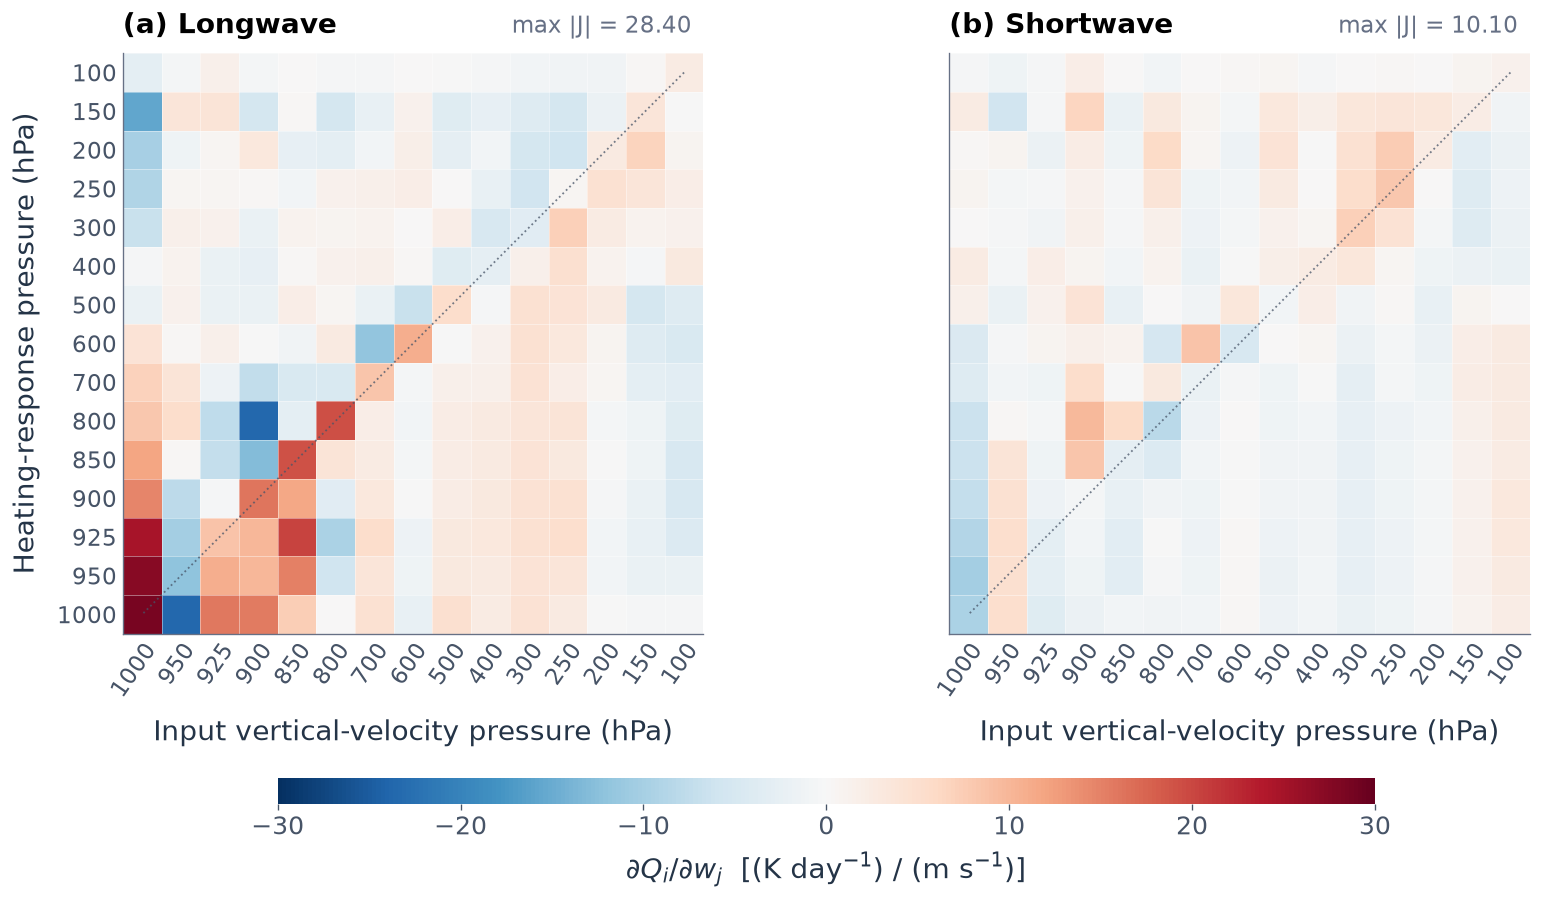

In [ ]:
# Equal-size cells display the discrete regression coefficients without smoothing.
pressure_labels = [f"{value:g}" for value in pressure_hpa]
limit = symmetric_limit(J_LW, J_SW)
jacobian_norm = TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 7.4), sharey=True, layout="constrained")

for ax, jacobian, title in zip(axes, (J_LW, J_SW), ("(a) Longwave", "(b) Shortwave")):
    jacobian = finite_array(jacobian)
    if jacobian.shape != (pressure_hpa.size, pressure_hpa.size):
        raise ValueError("Jacobian shape must match the pressure levels")
    mesh = ax.imshow(np.ma.masked_invalid(jacobian), cmap=heating_cmap,
                     norm=jacobian_norm, interpolation="nearest", origin="upper",
                     aspect="equal")
    index = np.arange(pressure_hpa.size)
    ax.set_xlim(pressure_hpa.size - 0.5, -0.5)  # 1000 hPa on the left
    ax.set_ylim(pressure_hpa.size - 0.5, -0.5)  # 1000 hPa at the bottom
    ax.set_xticks(index, pressure_labels, rotation=55, ha="right", rotation_mode="anchor")
    ax.set_yticks(index, pressure_labels)
    ax.tick_params(axis="both", which="major", length=0, labelsize=14)
    ax.set_xticks(np.arange(-0.5, pressure_hpa.size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, pressure_hpa.size, 1), minor=True)
    ax.grid(which="minor", color="white", lw=0.45, alpha=0.55)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.plot(index, index, color="#475467", ls=":", lw=1.1, alpha=0.75)
    ax.set_xlabel("Input vertical-velocity pressure (hPa)", labelpad=10)
    ax.set_title(title, pad=12)
    maximum = np.max(np.abs(jacobian[np.isfinite(jacobian)])) if np.isfinite(jacobian).any() else np.nan
    ax.text(0.98, 1.025, f"max |J| = {metric_label(maximum, 2)}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=14, color="#667085")

axes[0].set_ylabel("Heating-response pressure (hPa)", labelpad=10)
colorbar = fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=0.73,
                        pad=0.05, fraction=0.045, aspect=42)
colorbar.set_label(r"$\partial Q_i / \partial w_j$  [(K day$^{-1}$) / (m s$^{-1}$)]", labelpad=7)
colorbar.locator = MaxNLocator(nbins=7, symmetric=True)
colorbar.update_ticks()
colorbar.outline.set_visible(False)
save_verification_figure(fig, "Jacobian")
plt.show()
plt.close(fig)
